## 0. Setup and configuration

In [1]:
import os, sys, time, warnings, subprocess
try:
    import imblearn
except ImportError:                      # Colab usually needs this once
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    import imblearn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, accuracy_score,
                             roc_curve, precision_recall_curve)
from imblearn.pipeline import Pipeline as ImbPipeline      # NOT sklearn's Pipeline: it must resample
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
LEGIT, FRAUD = "#2A7F8E", "#E4572E"                          # one colour code used in every chart
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ---------------- configuration ----------------
RS = 42                                                      # global random seed
QUICK = os.environ.get("QUICK", "0") == "1"                  # True = fast smoke test
TUNE_FRAC = 0.10 if QUICK else 0.35                          # share of the training fold used for tuning
N_ITER_RF = 4 if QUICK else 10                               # random-search budget for the forest
CV_FOLDS = 3
RF_ABLATION_TREES = 30 if QUICK else 60
PERM_REPEATS = 2 if QUICK else 3
FP_COST = 5.0                                                # ASSUMPTION: cost of manually reviewing one false alert
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

print("scikit-learn / imbalanced-learn ready | QUICK =", QUICK)

scikit-learn / imbalanced-learn ready | QUICK = False


In [2]:
CANDIDATES = [os.environ.get("DATA_PATH", ""), "creditcard.csv", "data/creditcard.csv",
              "/content/creditcard.csv", "/kaggle/input/creditcardfraud/creditcard.csv"]
path = next((p for p in CANDIDATES if p and os.path.exists(p)), None)
if path is None and os.path.isdir("/kaggle/input"):          # Kaggle mounts datasets at varying sub-paths: search them all
    for root, _, files in os.walk("/kaggle/input"):
        if "creditcard.csv" in files:
            path = os.path.join(root, "creditcard.csv"); break
if path is None:
    raise FileNotFoundError("creditcard.csv not found. Put it next to this notebook, upload it in Colab, "
                            "or attach the 'Credit Card Fraud Detection' dataset in Kaggle.")
raw = pd.read_csv(path)
need = {"Time", "Amount", "Class"} | {f"V{i}" for i in range(1, 29)}
assert need.issubset(raw.columns), f"Unexpected schema, missing: {sorted(need - set(raw.columns))}"
print(f"Loaded {path}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded /kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv: 284,807 rows x 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 1. Data understanding

The course slides describe 284,807 transactions of which 0.17% are fraudulent. That matches the public *Credit Card Fraud Detection* dataset (`creditcard.csv`): `Time` (seconds since the first transaction), `V1`-`V28` (anonymised PCA components), `Amount`, and the label `Class` (1 = fraud). The notebook only **assumes this schema**; it checks for it below.

**Why this matters.** The PCA anonymisation means we cannot reason about merchants, countries or card types. Feature engineering is therefore limited to `Time`, `Amount` and geometry in the PCA space. This is a real constraint that I address openly in the limitations.

In [3]:
print("Missing values per column (total):", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print("Data types:", raw.dtypes.value_counts().to_dict())
counts = raw["Class"].value_counts().sort_index()
print(f"\nLegitimate: {counts[0]:,} ({counts[0]/len(raw):.3%}) | Fraud: {counts[1]:,} ({counts[1]/len(raw):.3%})")
print(f"Imbalance ratio: 1 fraud per {counts[0]/counts[1]:,.0f} legitimate transactions")
raw[["Time", "Amount"]].describe().T

Missing values per column (total): 0
Duplicate rows: 1081
Data types: {dtype('float64'): 30, dtype('int64'): 1}

Legitimate: 284,315 (99.827%) | Fraud: 492 (0.173%)
Imbalance ratio: 1 fraud per 578 legitimate transactions


,count,mean,std,min,25%,50%,75%,max
Time,"284,807.0000","94,813.8596","47,488.1460",0.0000,"54,201.5000","84,692.0000","139,320.5000","172,792.0000"
Amount,"284,807.0000",88.3496,250.1201,0.0000,5.6000,22.0000,77.1650,"25,691.1600"


## 2. Data cleaning

| Issue | Decision | Alternative | Trade-off |
|---|---|---|---|
| Exact duplicate rows | **Drop them** | Keep them | Duplicates can land in both train and test, which inflates test scores (a quiet form of leakage). The cost is losing a few rare fraud rows. |
| Missing values | None expected, but the modelling pipeline still contains a median `SimpleImputer` | Drop rows with NaN | A production feed can send nulls tomorrow. The imputer is fitted on training data only, so it is leak-free and keeps scoring from crashing. |
| Outliers | **Keep them** (analysed in section 3) | Cap or remove | Extreme amounts can be exactly the fraud we want to catch. |

In [4]:
before = len(raw)
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df):,} duplicate rows -> {len(df):,} rows remain")
print(f"Fraud rows after de-duplication: {int(df['Class'].sum()):,} ({df['Class'].mean():.3%})")
assert df.isna().sum().sum() == 0

Removed 1,081 duplicate rows -> 283,726 rows remain
Fraud rows after de-duplication: 473 (0.167%)


# Fraud Detection Pipeline: Supervised Learning on a Highly Imbalanced Dataset
**DecodeLabs Data Science Internship, Project 2 (Batch 2026)**

**Goal.** Build a leak-free, tuned classification pipeline (Logistic Regression and Random Forest, with SMOTE) that finds fraudulent card transactions, and judge it with Precision, Recall, F1, ROC-AUC and confusion matrices, **not** accuracy.

**How to read this notebook.** Every section states the decision, the alternatives considered, the trade-off, and the business impact. All numbers in the narrative are produced by the code cells, so nothing is hard-coded and the whole workflow is reproducible.

| # | Section |
|---|---|
| 1 | Data understanding |
| 2 | Data cleaning |
| 3 | Exploratory data analysis |
| 4 | Feature engineering |
| 5 | Train / validation / test split and leakage prevention |
| 6 | Class imbalance and SMOTE (including a leakage experiment) |
| 7 | Models: Logistic Regression and Random Forest |
| 8 | Hyperparameter tuning |
| 9 | Evaluation |
| 10 | Model comparison and selection |
| 11 | Feature importance |
| 12 | Business impact, recommendations, future work, conclusion |

**Runtime.** About 20-30 minutes on a free Colab/Kaggle CPU for the full run. Set the environment variable `QUICK=1` (or `QUICK = True` below) for a fast smoke test.

## 3. Exploratory data analysis
### 3.1 Class distribution

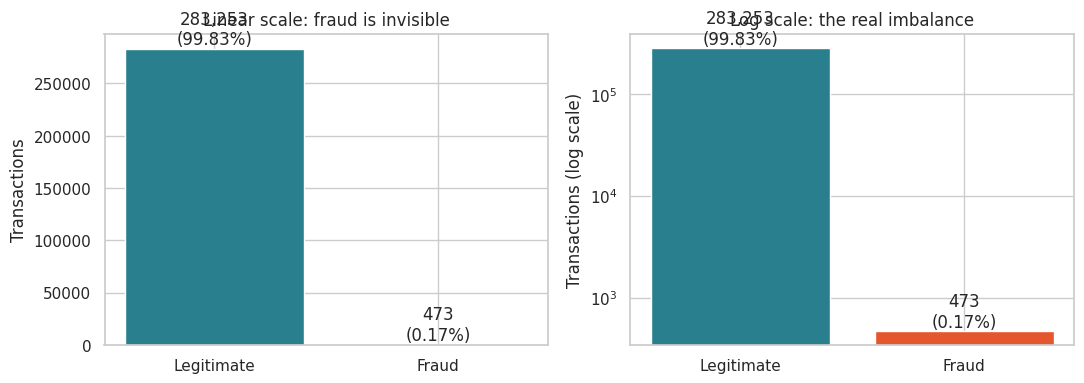

In [5]:
cnt = df["Class"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, log in zip(ax, [False, True]):
    bars = a.bar(["Legitimate", "Fraud"], cnt.values, color=[LEGIT, FRAUD])
    a.set_ylabel("Transactions" + (" (log scale)" if log else ""))
    if log: a.set_yscale("log")
    for b, v in zip(bars, cnt.values):
        a.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/len(df):.2%})", ha="center", va="bottom")
    a.set_title("Linear scale: fraud is invisible" if not log else "Log scale: the real imbalance")
savefig("01_class_distribution")

**Interpretation.** On the linear scale the fraud bar is almost invisible, which is the whole problem: a model that is rewarded for overall correctness can ignore it. **Business insight:** fraud is rare but expensive, so the cost of an error is wildly asymmetric. A missed fraud costs the transaction value plus chargeback fees; a false alarm costs a short review or a minor customer annoyance.

### 3.2 Why accuracy is misleading (demonstration)
A "model" that says *legitimate* for every transaction needs no learning at all. Look at what accuracy says about it.

In [6]:
always_legit = np.zeros(len(df), dtype=int)
print(f"Accuracy of 'always legitimate': {accuracy_score(df['Class'], always_legit):.4%}")
print(f"Recall   of 'always legitimate': {recall_score(df['Class'], always_legit):.1%}   <- catches ZERO fraud")
print(f"Precision: undefined (no fraud flagged), F1: {f1_score(df['Class'], always_legit, zero_division=0):.1f}")

Accuracy of 'always legitimate': 99.8333%
Recall   of 'always legitimate': 0.0%   <- catches ZERO fraud
Precision: undefined (no fraud flagged), F1: 0.0


This is why the rest of the notebook ignores accuracy and uses:

| Metric | Question it answers | Fraud meaning |
|---|---|---|
| **Precision** = TP/(TP+FP) | When we flag fraud, how often are we right? | Controls false declines and analyst workload |
| **Recall** = TP/(TP+FN) | Of all real fraud, how much did we catch? | Controls direct financial loss |
| **F1** | Harmonic mean of precision and recall | One number that cannot be gamed by sacrificing either side |
| **ROC-AUC** | Can the model rank fraud above legitimate regardless of threshold? | Threshold-free separability |
| **PR-AUC** (average precision) | Same ranking, but focused on the rare class | More honest than ROC-AUC under extreme imbalance because it ignores the huge pool of true negatives |
| **Confusion matrix** | The four outcomes in counts | Lets us price each error type in money |

I add PR-AUC to the required metrics and use it for hyper-parameter selection. ROC-AUC is still reported everywhere.

### 3.3 Transaction amount

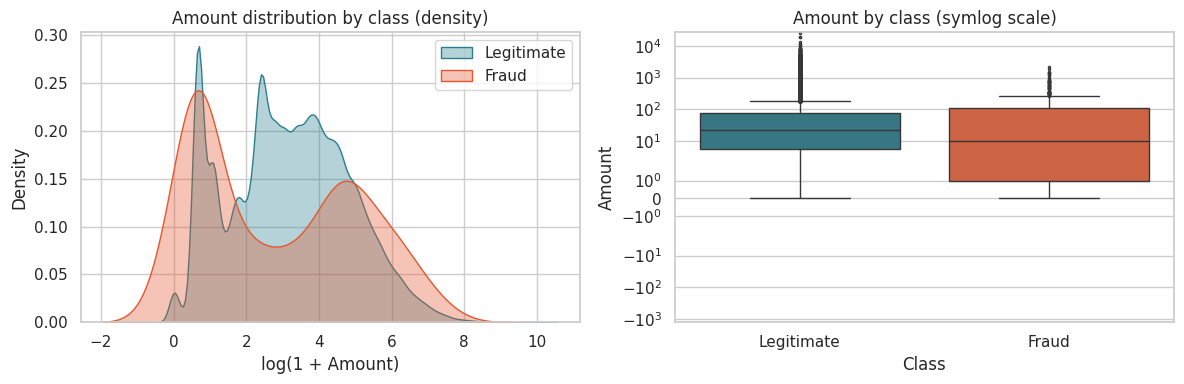

IQR upper fence: 185.38 | outliers overall: 11.17% | outliers among fraud: 18.39%
             count  median     mean         max
Class                                          
Legitimate  283253 22.0000  88.4136 25,691.1600
Fraud          473  9.8200 123.8719  2,125.8700


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cls, colr, lab in [(0, LEGIT, "Legitimate"), (1, FRAUD, "Fraud")]:
    sns.kdeplot(np.log1p(df.loc[df.Class == cls, "Amount"]), ax=ax[0], color=colr, fill=True, alpha=.35, label=lab, common_norm=False)
ax[0].set_xlabel("log(1 + Amount)"); ax[0].set_title("Amount distribution by class (density)"); ax[0].legend()
sns.boxplot(data=df, x="Class", y="Amount", ax=ax[1], palette=[LEGIT, FRAUD], showfliers=True, fliersize=1.5)
ax[1].set_yscale("symlog"); ax[1].set_xticklabels(["Legitimate", "Fraud"]); ax[1].set_title("Amount by class (symlog scale)")
savefig("02_amount_by_class")

q1, q3 = df["Amount"].quantile([.25, .75]); hi = q3 + 1.5*(q3 - q1)
out = df["Amount"] > hi
print(f"IQR upper fence: {hi:,.2f} | outliers overall: {out.mean():.2%} | outliers among fraud: {out[df.Class==1].mean():.2%}")
print(df.groupby("Class")["Amount"].agg(["count", "median", "mean", "max"]).rename(index={0:"Legitimate",1:"Fraud"}))

**Interpretation and decision.** Amounts are heavily right-skewed, so a log transform is appropriate for the linear model. The IQR rule flags a noticeable share of transactions as outliers, but compare the shares for legitimate and fraud rows above: removing or capping them would delete real signal and distort the very population we care about. **Decision: keep outliers, tame the skew with `log1p(Amount)`.** The trade-off is that the raw scale of `Amount` is lost for the linear model, which is acceptable because the log is monotonic, so rank information survives. Trees are unaffected either way.

### 3.4 Time of day
`Time` counts seconds from the first transaction (about two days). A raw elapsed-seconds value does not generalise to new days, but its position within a 24-hour cycle might.

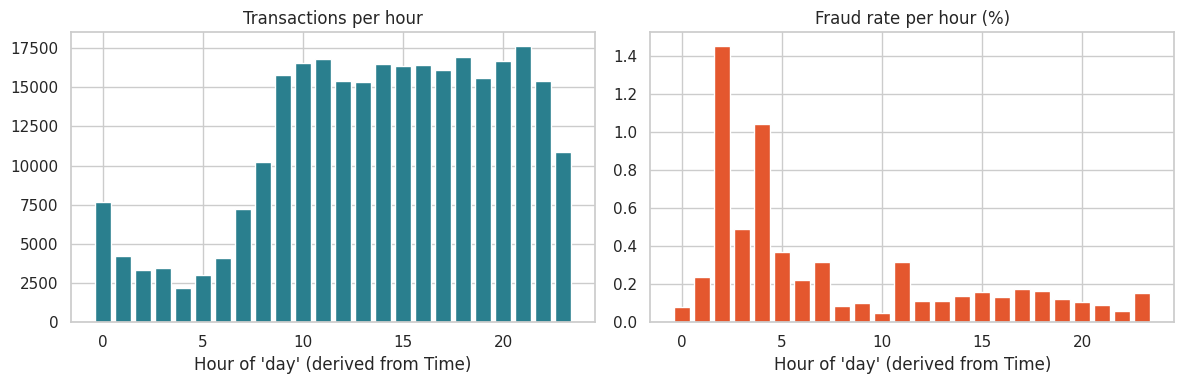

In [8]:
tmp = df.assign(hour=((df["Time"] // 3600) % 24).astype(int))
by_hour = tmp.groupby("hour")["Class"].agg(n="size", frauds="sum")
by_hour["fraud_rate_%"] = 100 * by_hour["frauds"] / by_hour["n"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(by_hour.index, by_hour["n"], color=LEGIT); ax[0].set_title("Transactions per hour"); ax[0].set_xlabel("Hour of 'day' (derived from Time)")
ax[1].bar(by_hour.index, by_hour["fraud_rate_%"], color=FRAUD); ax[1].set_title("Fraud rate per hour (%)"); ax[1].set_xlabel("Hour of 'day' (derived from Time)")
savefig("03_time_of_day")

**Interpretation.** Volume follows a daily rhythm. Where the fraud *rate* spikes (typically when volume is low), it suggests fraudsters operate when monitoring is thinner. Caveat: with only ~two days of data and a handful of frauds per hour, individual hourly rates are noisy, and the dataset does not tell us the clock time of `Time = 0`. I therefore treat the hour as a weak, cautiously used feature rather than a headline finding.

### 3.5 Correlation analysis
The `V` features are PCA outputs and therefore almost uncorrelated with each other by construction, so a full 30 x 30 heatmap would be nearly empty. The informative view is each feature's correlation with the label.

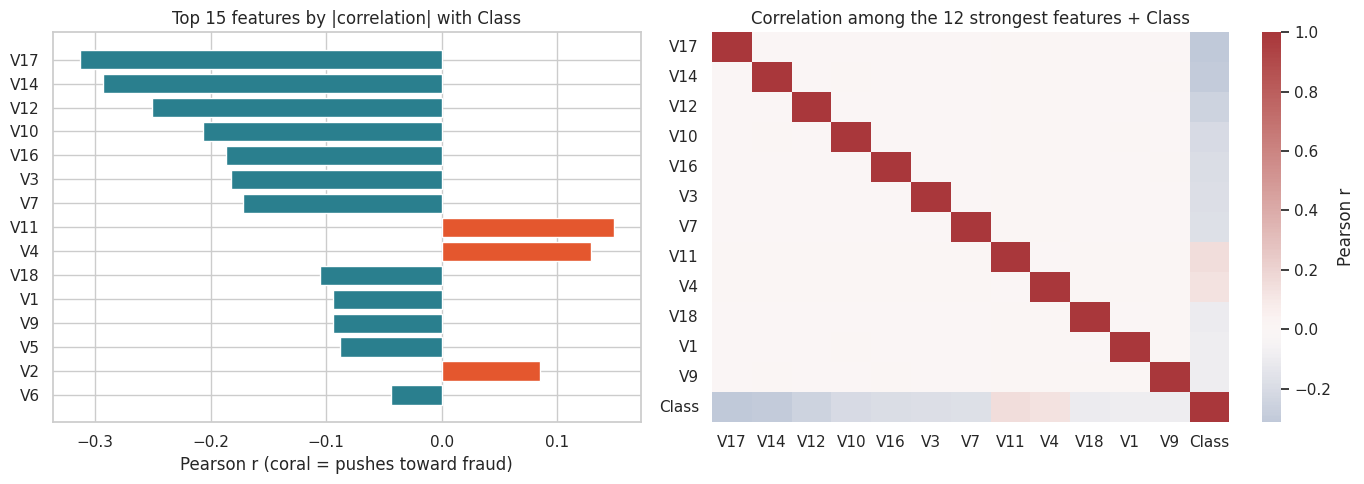

Largest |correlation| between any two V features: 0.019  (PCA => near zero => little multicollinearity)


In [9]:
corr_y = df.drop(columns="Class").corrwith(df["Class"]).sort_values(key=np.abs, ascending=False)
top = corr_y.index[:12]
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.1]})
colors = [FRAUD if v > 0 else LEGIT for v in corr_y.iloc[:15][::-1]]
ax[0].barh(corr_y.iloc[:15][::-1].index, corr_y.iloc[:15][::-1].values, color=colors)
ax[0].set_title("Top 15 features by |correlation| with Class"); ax[0].set_xlabel("Pearson r (coral = pushes toward fraud)")
sns.heatmap(df[list(top) + ["Class"]].corr(), cmap="vlag", center=0, annot=False, ax=ax[1], cbar_kws={"label": "Pearson r"})
ax[1].set_title("Correlation among the 12 strongest features + Class")
savefig("04_correlation")
off = df[[f"V{i}" for i in range(1, 29)]].corr().where(~np.eye(28, dtype=bool)).abs().max().max()
print(f"Largest |correlation| between any two V features: {off:.3f}  (PCA => near zero => little multicollinearity)")

**Interpretation and business insight.** A few components carry most of the linear signal (long bars). Their near-zero inter-correlation is good news for Logistic Regression because multicollinearity will not destabilise the coefficients. Pearson r only captures *linear* relationships, so a feature with a weak r can still matter to a non-linear model; that is one reason to compare against a Random Forest. For the business, the practical message is that a small subset of signals does most of the work, so monitoring and rule design should focus on them.

## 4. Feature engineering

All features below are **row-wise and stateless** (they compute nothing from other rows), so creating them before the split cannot leak information. Anything that needs statistics (scaling, imputing, resampling) is fitted inside the pipeline on training data only.

| Feature | Why it may help | Possible limitation |
|---|---|---|
| `hour` | Fraud may cluster when monitoring or customer activity is low | Clock offset of `Time = 0` unknown; only two days of data |
| `is_night` (hour 0-5) | A cheap, human-readable rule version of `hour` | Arbitrary window; correlated with `hour` |
| `log_amount` | Tames the heavy right skew so a linear model is not dominated by a few huge amounts | Loses the raw scale |
| `is_zero_amount` | Zero-value transactions are a known card-testing pattern | May be rare, so little support |
| `is_round_amount` | Fraudsters testing cards or cashing out often use round numbers | Legitimate round payments exist too |
| `v_norm` (L2 norm of V1-V28) | Distance from the "typical" origin of PCA space: an unusually unusual transaction | Mixes all components equally; PCA scaling differs by component |
| `v_absmax` (largest \|V\|) | Catches a transaction that is extreme on at least one dimension | Sensitive to a single noisy component |

I drop the raw `Time` (it does not generalise) and raw `Amount` (replaced by `log_amount`).

In [10]:
def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    # Stateless row-wise feature creation (safe to run before the train/test split).
    out = frame.copy()
    vcols = [f"V{i}" for i in range(1, 29)]
    out["hour"] = ((out["Time"] // 3600) % 24).astype(int)
    out["is_night"] = out["hour"].between(0, 5).astype(int)
    out["log_amount"] = np.log1p(out["Amount"])
    out["is_zero_amount"] = (out["Amount"] == 0).astype(int)
    out["is_round_amount"] = ((out["Amount"] % 1 == 0) & (out["Amount"] > 0)).astype(int)
    out["v_norm"] = np.sqrt((out[vcols] ** 2).sum(axis=1))
    out["v_absmax"] = out[vcols].abs().max(axis=1)
    return out.drop(columns=["Time", "Amount"])

df_fe = add_features(df)
new_feats = ["hour", "is_night", "log_amount", "is_zero_amount", "is_round_amount", "v_norm", "v_absmax"]
chk = df_fe[new_feats + ["Class"]]
print(chk.groupby("Class").mean().T.rename(columns={0: "mean | legit", 1: "mean | fraud"}))

Class            mean | legit  mean | fraud
hour                  14.0496       11.6554
is_night               0.0838        0.2431
log_amount             3.1543        2.8375
is_zero_amount         0.0063        0.0529
is_round_amount        0.2423        0.2918
v_norm                 4.7435       21.8932
v_absmax               2.4473       10.6704


**Interpretation.** Comparing the class means above is a first, crude read on whether a feature separates the classes (a notably higher `v_norm` for fraud, for example, would support the "unusually unusual" hypothesis). Whether each feature earns its place is judged properly in section 11 with permutation importance, not by eyeballing means.

## 5. Train / validation / test split and leakage prevention

**Design.**
1. **Test set (20%)**: touched once, at the very end.
2. From the remaining 80%, a **validation set (15% of it)** used only for choosing the decision threshold and the final model.
3. The rest is the **fit set**, used for cross-validated tuning and for training.

All splits are **stratified**, so every partition keeps the same tiny fraud rate. Without stratification a random split could leave the test set with almost no fraud.

**Leakage rules enforced in this notebook**
- Imputer, scaler and SMOTE live **inside** the `imblearn` pipeline and are fitted only on training folds.
- SMOTE is never applied to validation or test data; they keep the real-world imbalance.
- Model selection uses the validation set; the test set is only for the final report.
- `StandardScaler` is not used for the forest (trees are scale-invariant), but is used for Logistic Regression.

In [11]:
X = df_fe.drop(columns="Class"); y = df_fe["Class"]
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
X_fit, X_val, y_fit, y_val = train_test_split(X_trainval, y_trainval, test_size=0.15, stratify=y_trainval, random_state=RS)

split_tbl = pd.DataFrame({
    "rows": [len(y_fit), len(y_val), len(y_test)],
    "frauds": [int(y_fit.sum()), int(y_val.sum()), int(y_test.sum())],
}, index=["fit (train)", "validation", "test"])
split_tbl["fraud rate"] = split_tbl["frauds"] / split_tbl["rows"]
split_tbl

,rows,frauds,fraud rate
fit (train),192933,321,0.0017
validation,34047,57,0.0017
test,56746,95,0.0017


**Caveat to keep in mind.** The test set contains only a few dozen frauds, so every test metric carries real sampling noise: one extra missed fraud moves recall by a couple of percentage points. I report that uncertainty explicitly in section 9 rather than pretending to false precision.

## 6. Class imbalance and SMOTE

**Options compared**

| Technique | How | Weakness |
|---|---|---|
| Random undersampling | Delete legitimate rows | Throws away most of the data |
| Random oversampling | Duplicate fraud rows | The model memorises exact copies, so it overfits |
| `class_weight="balanced"` | Re-weight the loss | No new information, but cheap and leak-free (used as an ablation below) |
| **SMOTE** | Create *new* fraud points by interpolating between a fraud case and one of its nearest fraud neighbours | Can generate points in noisy or overlapping regions; needs scaled, numeric features |

SMOTE builds each synthetic point as

$$x_{new} = x_i + \lambda\,(x_{nn} - x_i),\qquad \lambda\sim U(0,1)$$

where $x_i$ is a real fraud and $x_{nn}$ is one of its `k` nearest fraud neighbours. SMOTE uses distances, which is why the scaler comes **before** it in the pipeline.

### Why applying SMOTE before splitting is wrong
SMOTE would create synthetic fraud points from the whole dataset, so a synthetic point in the *test* set could be an interpolation of two *training* frauds (or vice versa). The test set stops being unseen: the model is graded on near-copies of what it studied, and the test set also becomes artificially balanced, which flatters precision. Scores look great and then collapse in production. Section 6.2 proves this on our own data.

### 6.1 SMOTE on the training fold only: before and after

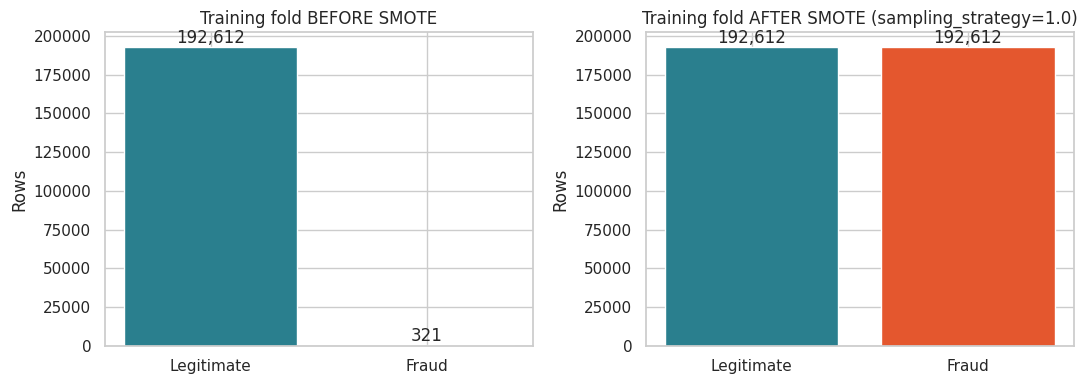

Validation fraud rate (untouched): 0.167% | Test fraud rate (untouched): 0.167%


In [12]:
scaler_demo = StandardScaler().fit(X_fit)                                  # fitted on training data only
Xs = scaler_demo.transform(X_fit)
sm = SMOTE(random_state=RS)
Xs_res, y_res = sm.fit_resample(Xs, y_fit)

before, after = y_fit.value_counts().sort_index(), pd.Series(y_res).value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for a, s, t in [(ax[0], before, "Training fold BEFORE SMOTE"), (ax[1], after, "Training fold AFTER SMOTE (sampling_strategy=1.0)")]:
    bars = a.bar(["Legitimate", "Fraud"], s.values, color=[LEGIT, FRAUD]); a.set_title(t); a.set_ylabel("Rows")
    for b, v in zip(bars, s.values): a.text(b.get_x()+b.get_width()/2, v, f"{v:,}", ha="center", va="bottom")
savefig("05_smote_before_after")
print(f"Validation fraud rate (untouched): {y_val.mean():.3%} | Test fraud rate (untouched): {y_test.mean():.3%}")

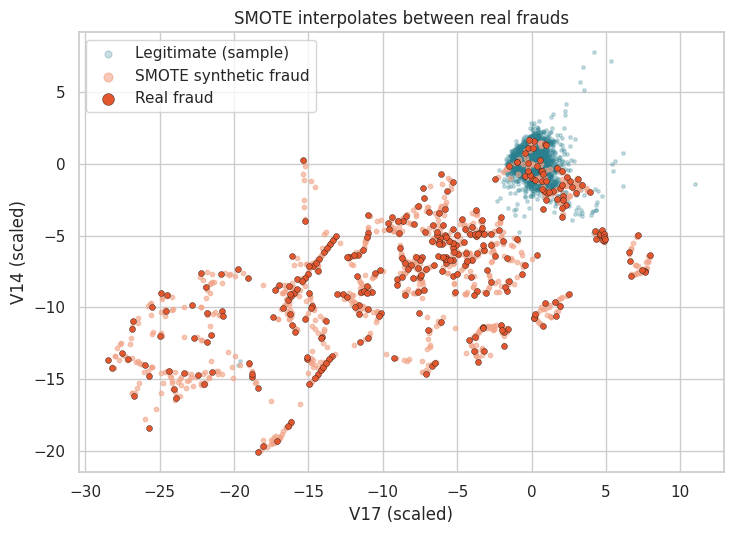

In [13]:
# Visualise what SMOTE actually does in 2-D, using the two features most correlated with Class.
f1_, f2_ = [c for c in corr_y.index if c.startswith("V")][:2]
cols2 = [X_fit.columns.get_loc(f1_), X_fit.columns.get_loc(f2_)]
P = Xs[:, cols2]; P_res, y2 = SMOTE(random_state=RS).fit_resample(P, y_fit)
n0 = len(P); real_fraud = P[y_fit.values == 1]; synth = P_res[n0:]
rng = np.random.default_rng(RS); legit_s = P[rng.choice(np.where(y_fit.values == 0)[0], 3000, replace=False)]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(*legit_s.T, s=6, c=LEGIT, alpha=.25, label="Legitimate (sample)")
ax.scatter(*synth[rng.choice(len(synth), min(1500, len(synth)), replace=False)].T, s=10, c="#F2A488", alpha=.6, label="SMOTE synthetic fraud")
ax.scatter(*real_fraud.T, s=18, c=FRAUD, edgecolor="k", linewidth=.3, label="Real fraud")
ax.set_xlabel(f"{f1_} (scaled)"); ax.set_ylabel(f"{f2_} (scaled)"); ax.set_title("SMOTE interpolates between real frauds"); ax.legend(markerscale=2)
savefig("06_smote_scatter")

**Interpretation.** Synthetic points (light coral) fill the space *between* real frauds (dark coral) instead of stacking copies on top of them. That gives the classifier a smoother, wider fraud region to learn. The risk is visible too: where the fraud region overlaps the legitimate cloud, synthetic points can land in ambiguous territory and teach the model to over-flag. That is why the amount of oversampling (`sampling_strategy`) is tuned later rather than fixed at full 1:1.

### 6.2 Experiment: the cost of getting the order wrong
Same data, same Logistic Regression. The only difference is *when* SMOTE is applied.

In [14]:
def quick_lr():
    return LogisticRegression(max_iter=500, solver="lbfgs")

# (A) WRONG: scale + SMOTE on everything, then split.
Xall_s = StandardScaler().fit_transform(X)                                 # scaler sees test rows too
Xall_r, yall_r = SMOTE(random_state=RS).fit_resample(Xall_s, y)
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xall_r, yall_r, test_size=0.2, stratify=yall_r, random_state=RS)
pa = quick_lr().fit(Xa_tr, ya_tr).predict_proba(Xa_te)[:, 1]

# (B) RIGHT: split first, SMOTE only inside the training data, test on untouched imbalanced data.
pipe_b = ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=RS)), ("clf", quick_lr())])
pb = pipe_b.fit(X_fit, y_fit).predict_proba(X_test)[:, 1]

def row(y_true, p):
    pred = (p >= .5).astype(int)
    return dict(precision=precision_score(y_true, pred, zero_division=0), recall=recall_score(y_true, pred),
                f1=f1_score(y_true, pred), roc_auc=roc_auc_score(y_true, p), pr_auc=average_precision_score(y_true, p))
leak_tbl = pd.DataFrame({"WRONG: SMOTE before split": row(ya_te, pa), "RIGHT: SMOTE inside training only": row(y_test, pb)}).T
leak_tbl

,precision,recall,f1,roc_auc,pr_auc
WRONG: SMOTE before split,0.9727,0.9264,0.9489,0.9899,0.9914
RIGHT: SMOTE inside training only,0.0466,0.8632,0.0884,0.9511,0.7055


**Interpretation.** The "wrong" row is evaluated on a test set that is half synthetic fraud and contains neighbours of training points, so its precision, F1 and PR-AUC are inflated. The "right" row is evaluated on realistic, untouched data. **The honest number is the lower one**; a manager shown the inflated number would approve a system that underperforms in production. This single experiment is the strongest argument for the `imblearn` pipeline used below.

## 7. Models

### Logistic Regression
**Intuition.** Models the log-odds of fraud as a weighted sum of the features, $\;\log\frac{p}{1-p}=w_0+\sum_j w_j x_j$, then squashes it with the sigmoid to get a probability. Weights are learned by minimising log-loss plus an L2 penalty $\frac{1}{2C}\lVert w\rVert^2$.
- **Strengths:** fast, stable, calibrated-ish probabilities, and every coefficient has a direction and size an auditor can read.
- **Weaknesses:** a single linear boundary; cannot capture interactions unless engineered; **needs scaling** because the penalty treats all coefficients equally.
- **Expected behaviour in fraud:** a strong, transparent baseline. Often high recall but lower precision, especially after SMOTE, because the oversampled fraud region pulls the boundary toward the legitimate class.

### Random Forest
**Intuition.** Averages many decision trees, each grown on a bootstrap sample with a random subset of features at each split. Trees carve the space with axis-aligned cuts; averaging reduces variance.
- **Strengths:** captures non-linear effects and interactions, robust to outliers, no scaling needed, built-in importance.
- **Weaknesses:** slower to train and score, larger memory, less transparent, can overfit noisy synthetic points, and probabilities are coarser.
- **Expected behaviour in fraud:** usually higher precision at similar recall, because it can isolate tight fraud pockets that a single hyperplane cannot.

### 7.1 Ablation: does imbalance handling help, and which kind?
On the validation set (default threshold 0.5, default-ish hyper-parameters) I compare no handling, `class_weight="balanced"` and SMOTE for both models. The purpose is to justify SMOTE with evidence instead of assuming it.

In [15]:
def make_pipe(model, smote=False, scale=False, smote_kw=None):
    steps = [("imputer", SimpleImputer(strategy="median"))]            # fitted on training data only
    if scale: steps.append(("scaler", StandardScaler()))
    if smote: steps.append(("smote", SMOTE(random_state=RS, **(smote_kw or {}))))
    steps.append(("clf", model))
    return ImbPipeline(steps)

def metrics_at(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(precision=precision_score(y_true, pred, zero_division=0), recall=recall_score(y_true, pred),
                f1=f1_score(y_true, pred), roc_auc=roc_auc_score(y_true, proba),
                pr_auc=average_precision_score(y_true, proba), tn=tn, fp=fp, fn=fn, tp=tp, threshold=thr)

def rf(**kw):
    return RandomForestClassifier(n_estimators=RF_ABLATION_TREES, max_depth=12, n_jobs=-1, random_state=RS, **kw)

abl = {
 "LogReg | none":        make_pipe(LogisticRegression(max_iter=1000), scale=True),
 "LogReg | class_weight": make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"), scale=True),
 "LogReg | SMOTE":       make_pipe(LogisticRegression(max_iter=1000), smote=True, scale=True),
 "RandForest | none":        make_pipe(rf()),
 "RandForest | class_weight": make_pipe(rf(class_weight="balanced_subsample")),
 "RandForest | SMOTE":       make_pipe(rf(), smote=True),
}
rows = {}
for name, pipe in abl.items():
    t0 = time.perf_counter(); pipe.fit(X_fit, y_fit)
    rows[name] = {**metrics_at(y_val, pipe.predict_proba(X_val)[:, 1]), "fit_s": time.perf_counter() - t0}
abl_df = pd.DataFrame(rows).T
abl_df[["precision", "recall", "f1", "roc_auc", "pr_auc", "fp", "fn", "fit_s"]]

,precision,recall,f1,roc_auc,pr_auc,fp,fn,fit_s
LogReg | none,0.9286,0.6842,0.7879,0.9727,0.7994,3.0000,18.0000,2.3037
LogReg | class_weight,0.0545,0.9123,0.1028,0.9884,0.8031,903.0000,5.0000,3.5642
LogReg | SMOTE,0.0495,0.8947,0.0938,0.9865,0.7899,980.0000,6.0000,5.5637
RandForest | none,0.9412,0.8421,0.8889,0.9494,0.8761,3.0000,9.0000,40.0152
RandForest | class_weight,0.8889,0.8421,0.8649,0.9519,0.8489,6.0000,9.0000,28.0277
RandForest | SMOTE,0.6533,0.8596,0.7424,0.9773,0.8526,26.0000,8.0000,74.0251


**How to read the table.** Look at the *shape* of the change, not tiny differences, because the validation set holds few frauds. Typically SMOTE and class weights **raise recall** relative to doing nothing, usually at the price of precision (more false alarms); this is the precision-recall trade-off in action. Whichever imbalance strategy wins here, the project brief requires SMOTE, so the tuned models below keep it in the pipeline and tune *how much* of it to apply.

## 8. Hyper-parameter tuning

**Method.** `GridSearchCV` (small, exhaustive grid) for Logistic Regression and `RandomizedSearchCV` (budgeted search over a larger space) for the Random Forest. The `SMOTE` step sits **inside** the `imblearn` pipeline, so for every candidate and every fold it is fitted on the training part only and the validation part stays untouched ("golden rule of validation").

**Scoring.** The selection metric is **PR-AUC (average precision)**. I also record ROC-AUC, recall and precision per fold. PR-AUC is chosen because ROC-AUC can look excellent under extreme imbalance simply thanks to the enormous number of true negatives.

**Compute trade-off.** Tuning runs on a stratified `TUNE_FRAC` subset of the fit set so a free CPU can finish. The cost is somewhat noisier tuning; the winners are then **re-trained on the full fit set**.

| Parameter | Why it matters | Effect when increased |
|---|---|---|
| `clf__C` (LR) | Inverse regularisation strength | Higher C = weaker penalty, a more flexible, more over-fit-prone boundary |
| `smote__sampling_strategy` | Final fraud:legit ratio after SMOTE | Higher = more recall, usually lower precision; 1.0 is full balance |
| `smote__k_neighbors` | Neighbours used to interpolate | Higher = smoother, safer synthetic points; lower = tighter to real cases |
| `clf__n_estimators` (RF) | Number of trees | More trees = lower variance, slower |
| `clf__max_depth` (RF) | Tree depth | Deeper = lower bias, higher over-fit risk |
| `clf__min_samples_leaf` (RF) | Minimum leaf size | Larger = smoother, more conservative trees |
| `clf__max_features` (RF) | Features per split | Smaller = more diverse trees |
| `clf__class_weight` (RF) | Extra loss weight on fraud | Complements SMOTE; may over-flag if combined with full balance |

In [16]:
X_tune, _, y_tune, _ = train_test_split(X_fit, y_fit, train_size=TUNE_FRAC, stratify=y_fit, random_state=RS)
print(f"Tuning subset: {len(y_tune):,} rows, {int(y_tune.sum())} frauds ({y_tune.mean():.3%})")
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RS)
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall", "precision": "precision"}

lr_base = make_pipe(LogisticRegression(max_iter=1000), smote=True, scale=True)
lr_grid = {"clf__C": [0.01, 0.1, 1, 10],
           "smote__sampling_strategy": [0.1, 0.5, 1.0],
           "smote__k_neighbors": [3, 5]}
t0 = time.perf_counter()
lr_search = GridSearchCV(lr_base, lr_grid, scoring=scoring, refit="pr_auc", cv=cv, n_jobs=1, error_score="raise")
lr_search.fit(X_tune, y_tune)
print(f"LogReg grid search: {len(lr_search.cv_results_['params'])} candidates x {CV_FOLDS} folds in {time.perf_counter()-t0:,.0f}s")
print("Best params:", lr_search.best_params_, "| CV PR-AUC:", round(lr_search.best_score_, 4))

Tuning subset: 67,526 rows, 112 frauds (0.166%)
LogReg grid search: 24 candidates x 3 folds in 90s
Best params: {'clf__C': 0.01, 'smote__k_neighbors': 5, 'smote__sampling_strategy': 0.1} | CV PR-AUC: 0.7755


In [17]:
rf_base = make_pipe(RandomForestClassifier(n_jobs=-1, random_state=RS), smote=True)
rf_space = {"clf__n_estimators": [100, 200],
            "clf__max_depth": [8, 12, 16, 24],
            "clf__min_samples_leaf": [1, 2, 5],
            "clf__max_features": ["sqrt", 0.3],
            "clf__class_weight": [None, "balanced_subsample"],
            "smote__sampling_strategy": [0.05, 0.1, 0.3, 0.5],
            "smote__k_neighbors": [3, 5, 7]}
t0 = time.perf_counter()
rf_search = RandomizedSearchCV(rf_base, rf_space, n_iter=N_ITER_RF, scoring=scoring, refit="pr_auc",
                               cv=cv, n_jobs=1, random_state=RS, error_score="raise")
rf_search.fit(X_tune, y_tune)
print(f"RandomForest random search: {N_ITER_RF} candidates x {CV_FOLDS} folds in {time.perf_counter()-t0:,.0f}s")
print("Best params:", rf_search.best_params_, "| CV PR-AUC:", round(rf_search.best_score_, 4))

RandomForest random search: 10 candidates x 3 folds in 1,034s
Best params: {'smote__sampling_strategy': 0.05, 'smote__k_neighbors': 3, 'clf__n_estimators': 200, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 24, 'clf__class_weight': 'balanced_subsample'} | CV PR-AUC: 0.8397


In [18]:
def top_table(search, n=5):
    r = pd.DataFrame(search.cv_results_)
    keep = ["params", "mean_test_pr_auc", "mean_test_roc_auc", "mean_test_recall", "mean_test_precision", "rank_test_pr_auc"]
    t = r[keep].sort_values("rank_test_pr_auc").head(n).copy()
    t["params"] = t["params"].apply(lambda d: {k.split("__")[-1]: v for k, v in d.items()})
    return t
print("Logistic Regression: top 5 candidates (cross-validated on the tuning subset)")
display(top_table(lr_search))
print("Random Forest: top 5 candidates")
display(top_table(rf_search))

Logistic Regression: top 5 candidates (cross-validated on the tuning subset)


,params,mean_test_pr_auc,mean_test_roc_auc,mean_test_recall,mean_test_precision,rank_test_pr_auc
3,"{'C': 0.01, 'k_neighbors': 5, 'sampling_strate...",0.7755,0.9838,0.8656,0.4295,1
0,"{'C': 0.01, 'k_neighbors': 3, 'sampling_strate...",0.7731,0.9822,0.8656,0.4349,2
14,"{'C': 1, 'k_neighbors': 3, 'sampling_strategy'...",0.7719,0.9770,0.8658,0.0900,3
17,"{'C': 1, 'k_neighbors': 5, 'sampling_strategy'...",0.7717,0.9776,0.8658,0.0864,4
20,"{'C': 10, 'k_neighbors': 3, 'sampling_strategy...",0.7710,0.9770,0.8658,0.0904,5


Random Forest: top 5 candidates


,params,mean_test_pr_auc,mean_test_roc_auc,mean_test_recall,mean_test_precision,rank_test_pr_auc
4,"{'sampling_strategy': 0.05, 'k_neighbors': 3, ...",0.8397,0.9725,0.7949,0.9021,1
7,"{'sampling_strategy': 0.3, 'k_neighbors': 5, '...",0.8361,0.9851,0.8037,0.8844,2
5,"{'sampling_strategy': 0.1, 'k_neighbors': 3, '...",0.8357,0.9832,0.8125,0.8612,3
9,"{'sampling_strategy': 0.5, 'k_neighbors': 5, '...",0.8314,0.9766,0.7949,0.9021,4
6,"{'sampling_strategy': 0.3, 'k_neighbors': 7, '...",0.8289,0.9794,0.8125,0.8838,5


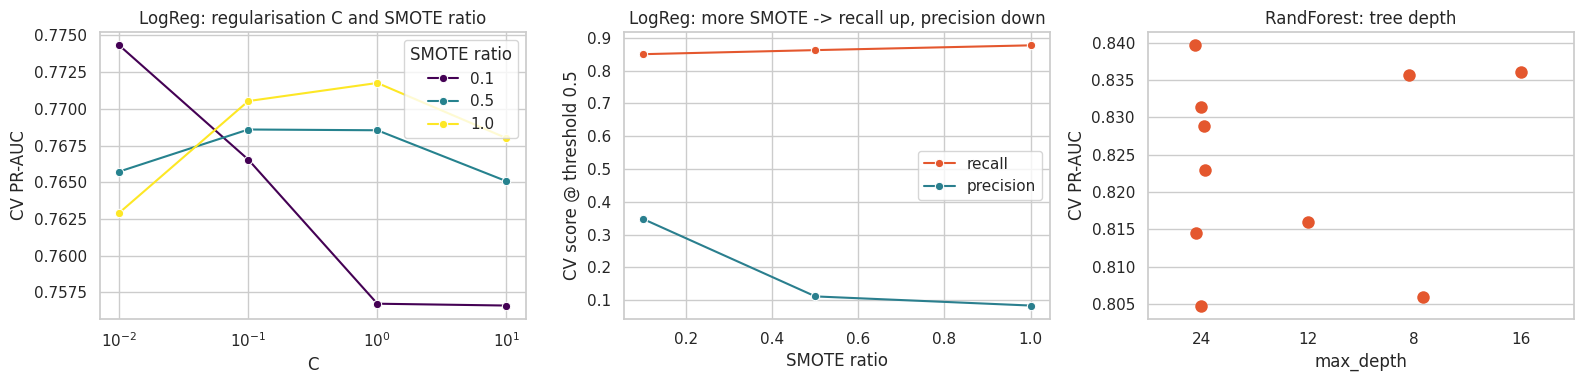

In [19]:
# How do the key hyper-parameters move the score? (cross-validated PR-AUC)
r_lr = pd.DataFrame(lr_search.cv_results_); r_lr["C"] = r_lr["param_clf__C"].astype(float)
r_lr["SMOTE ratio"] = r_lr["param_smote__sampling_strategy"].astype(float)
r_rf = pd.DataFrame(rf_search.cv_results_)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.lineplot(data=r_lr, x="C", y="mean_test_pr_auc", hue="SMOTE ratio", marker="o", ax=ax[0], palette="viridis", errorbar=None)
ax[0].set_xscale("log"); ax[0].set_title("LogReg: regularisation C and SMOTE ratio"); ax[0].set_ylabel("CV PR-AUC")
sns.lineplot(data=r_lr, x="SMOTE ratio", y="mean_test_recall", marker="o", ax=ax[1], color=FRAUD, errorbar=None, label="recall")
sns.lineplot(data=r_lr, x="SMOTE ratio", y="mean_test_precision", marker="o", ax=ax[1], color=LEGIT, errorbar=None, label="precision")
ax[1].set_title("LogReg: more SMOTE -> recall up, precision down"); ax[1].set_ylabel("CV score @ threshold 0.5")
sns.stripplot(data=r_rf.assign(depth=r_rf["param_clf__max_depth"].astype(str)), x="depth", y="mean_test_pr_auc", ax=ax[2], color=FRAUD, size=9)
ax[2].set_title("RandForest: tree depth"); ax[2].set_xlabel("max_depth"); ax[2].set_ylabel("CV PR-AUC")
savefig("07_tuning_effects")

**Interpretation.** Left: PR-AUC across the regularisation range shows how sensitive the linear model is to `C`. Middle: the clearest trade-off in the whole project: as SMOTE pushes the fraud share up, recall tends to rise while precision falls, so `sampling_strategy` is effectively a *business dial* between "catch more fraud" and "bother fewer customers". Right: how the forest responds to depth; with a small random-search budget, read this as a trend, not a proof.

**Business insight.** Choosing a hyper-parameter set is not purely technical. The SMOTE ratio and decision threshold encode how much the institution is willing to pay in false alarms to avoid missed fraud.

### 8.1 Final training on the full fit set, threshold selection on validation
The best configuration of each model is re-trained on the entire fit set. The default 0.5 probability cut-off is arbitrary, especially after resampling changes the class prior, so I pick the threshold that maximises **F1 on the validation set** (never on the test set).

In [20]:
def fit_final(search):
    est = clone(search.best_estimator_)                  # same hyper-parameters, unfitted
    t0 = time.perf_counter(); est.fit(X_fit, y_fit)
    return est, time.perf_counter() - t0

def best_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return float(t[int(np.nanargmax(f1))])

final = {}
for name, search in [("Logistic Regression", lr_search), ("Random Forest", rf_search)]:
    est, fit_s = fit_final(search)
    p_val = est.predict_proba(X_val)[:, 1]
    thr = best_threshold(y_val, p_val)
    t0 = time.perf_counter(); p_test = est.predict_proba(X_test)[:, 1]; score_ms = 1000 * (time.perf_counter() - t0) / len(X_test) * 1000
    final[name] = dict(est=est, fit_s=fit_s, p_val=p_val, p_test=p_test, thr=thr, ms_per_1000=score_ms,
                       val=metrics_at(y_val, p_val, thr), params=search.best_params_)
    print(f"{name}: fit {fit_s:,.0f}s | scoring {score_ms:.1f} ms per 1,000 rows | F1-optimal validation threshold = {thr:.3f}")

Logistic Regression: fit 3s | scoring 0.7 ms per 1,000 rows | F1-optimal validation threshold = 0.997
Random Forest: fit 122s | scoring 7.6 ms per 1,000 rows | F1-optimal validation threshold = 0.611


## 9. Evaluation on the untouched test set

Each model is shown at two operating points: the conventional **0.5** cut-off and the **validation-tuned** threshold. ROC-AUC and PR-AUC do not depend on the threshold.

In [21]:
rows = []
for name, d in final.items():
    for label, thr in [("threshold 0.5", 0.5), (f"tuned ({d['thr']:.3f})", d["thr"])]:
        m = metrics_at(y_test, d["p_test"], thr); m.update(model=name, operating_point=label); rows.append(m)
res = pd.DataFrame(rows).set_index(["model", "operating_point"])
display(res[["precision", "recall", "f1", "roc_auc", "pr_auc", "tp", "fp", "fn", "tn"]])

precision  recall     f1  roc_auc  \
model               operating_point                                      
Logistic Regression threshold 0.5       0.4611  0.8105 0.5878   0.9545   
                    tuned (0.997)       0.8714  0.6421 0.7394   0.9545   
Random Forest       threshold 0.5       0.8974  0.7368 0.8092   0.9570   
                    tuned (0.611)       0.9324  0.7263 0.8166   0.9570   

                                     pr_auc  tp  fp  fn     tn  
model               operating_point                             
Logistic Regression threshold 0.5    0.7050  77  90  18  56561  
                    tuned (0.997)    0.7050  61   9  34  56642  
Random Forest       threshold 0.5    0.8134  70   8  25  56643  
                    tuned (0.611)    0.8134  69   5  26  56646

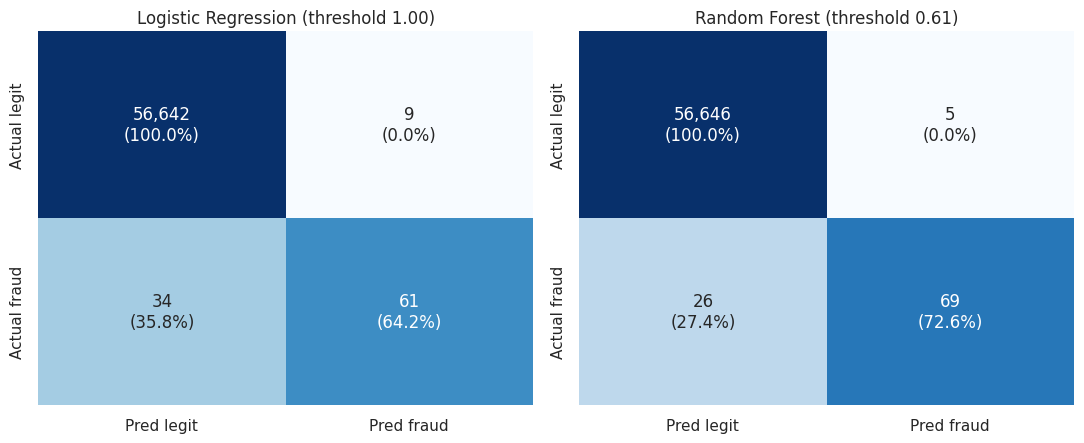

In [22]:
# Confusion matrices at the tuned threshold (counts, with row-normalised % underneath)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (name, d) in zip(ax, final.items()):
    m = metrics_at(y_test, d["p_test"], d["thr"]); cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    pct = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i,j]:,}\n({pct[i,j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", cbar=False, ax=a, vmin=0, vmax=1,
                xticklabels=["Pred legit", "Pred fraud"], yticklabels=["Actual legit", "Actual fraud"])
    a.set_title(f"{name} (threshold {d['thr']:.2f})")
savefig("08_confusion_matrices")

**Interpretation in business terms.**
- **Bottom-left cell (false negatives):** fraud that slips through. Each is direct money lost plus chargeback and reputational cost. This is the cell the business fears most.
- **Top-right cell (false positives):** good customers flagged. Each costs analyst time and, if the card is auto-declined, customer trust. At scale a low-precision model can drown the fraud team in alerts, so there is an operational ceiling on how many false alarms are tolerable.
- Colours show the *row-normalised* rate, so the 99%+ legitimate row does not hide the fraud row.

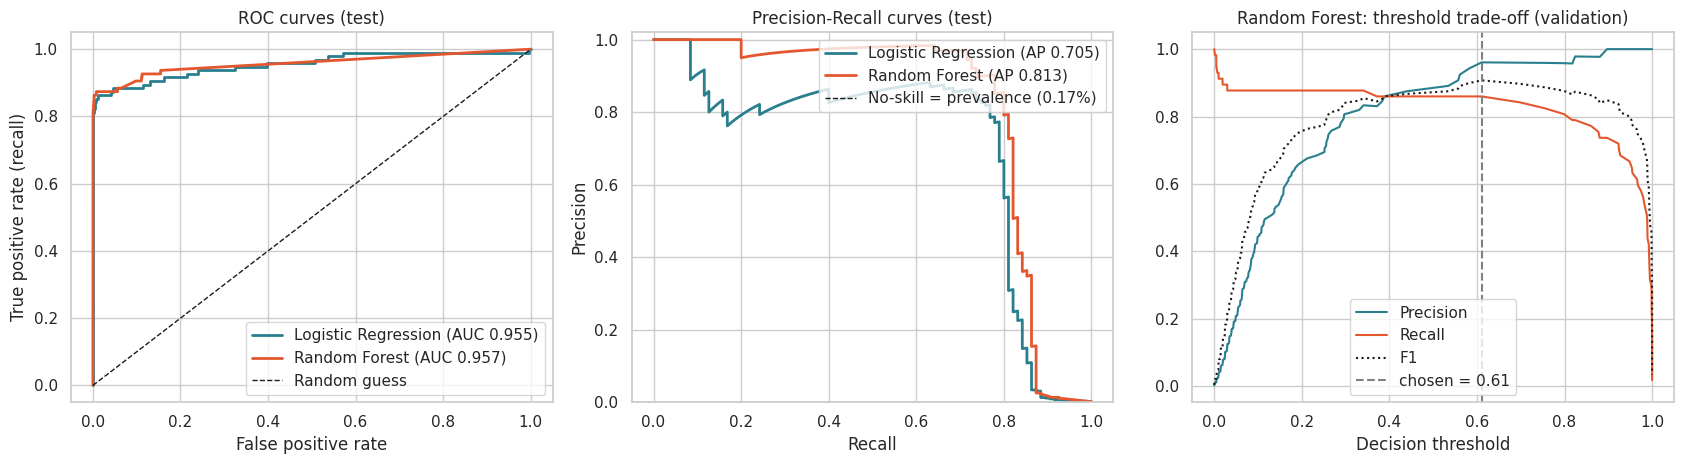

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
colors = {"Logistic Regression": LEGIT, "Random Forest": FRAUD}
for name, d in final.items():
    fpr, tpr, _ = roc_curve(y_test, d["p_test"]); ax[0].plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC {roc_auc_score(y_test, d['p_test']):.3f})")
    p, r, _ = precision_recall_curve(y_test, d["p_test"]); ax[1].plot(r, p, color=colors[name], lw=2, label=f"{name} (AP {average_precision_score(y_test, d['p_test']):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].set_title("ROC curves (test)"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"No-skill = prevalence ({y_test.mean():.2%})"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall curves (test)"); ax[1].legend(loc="upper right")
ax[1].set_ylim(0, 1.02)
w = final["Random Forest"]; pv, rv, tv = precision_recall_curve(y_val, w["p_val"])
ax[2].plot(tv, pv[:-1], color=LEGIT, label="Precision"); ax[2].plot(tv, rv[:-1], color=FRAUD, label="Recall")
ax[2].plot(tv, 2*pv[:-1]*rv[:-1]/(pv[:-1]+rv[:-1]+1e-12), color="k", ls=":", label="F1"); ax[2].axvline(w["thr"], color="gray", ls="--", label=f"chosen = {w['thr']:.2f}")
ax[2].set_xlabel("Decision threshold"); ax[2].set_title("Random Forest: threshold trade-off (validation)"); ax[2].legend()
savefig("09_roc_pr_threshold")

**Interpretation.**
- **ROC curves** that hug the top-left corner mean good ranking, but note how quickly they approach the ceiling: ROC-AUC looks flattering on imbalanced data.
- **Precision-Recall curves** are the sterner test; the dashed line is what a useless model would score (the fraud prevalence). The gap between each curve and that line is the real value added.
- **Threshold chart:** moving the threshold slides us along the trade-off. Lower = more recall, more false alarms; higher = the reverse. The chosen threshold is where F1 peaks on *validation* data. A bank with a high cost of fraud and cheap review could deliberately pick a lower threshold.

**Statistical honesty: how uncertain are these numbers?** With so few test frauds, I bootstrap the test set to put an interval around recall and precision.

In [24]:
def boot_ci(y_true, proba, thr, n=1000, seed=RS):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); idx = np.arange(len(y_true)); out = []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        yt, pr = y_true[s], (proba[s] >= thr).astype(int)
        out.append((precision_score(yt, pr, zero_division=0), recall_score(yt, pr, zero_division=0), f1_score(yt, pr, zero_division=0)))
    return np.percentile(np.array(out), [2.5, 97.5], axis=0)
ci_rows = {}
for name, d in final.items():
    lo, hi = boot_ci(y_test, d["p_test"], d["thr"])
    ci_rows[name] = {f"{m} 95% CI": f"{lo[i]:.2f} - {hi[i]:.2f}" for i, m in enumerate(["precision", "recall", "F1"])}
pd.DataFrame(ci_rows).T

,precision 95% CI,recall 95% CI,F1 95% CI
Logistic Regression,0.79 - 0.94,0.54 - 0.73,0.66 - 0.81
Random Forest,0.87 - 0.99,0.64 - 0.81,0.75 - 0.87


**Interpretation.** The intervals are wide. A difference of a few points between the two models is **not** statistically meaningful on a test set this small; only large gaps or consistent patterns across precision, recall, ROC-AUC and PR-AUC should drive the choice. This is also why model selection below uses the larger validation split and several metrics together.

## 10. Model comparison and final selection

In [25]:
cmp = []
for name, d in final.items():
    m = metrics_at(y_test, d["p_test"], d["thr"]); v = d["val"]
    cmp.append({"Model": name, "Precision": m["precision"], "Recall": m["recall"], "F1": m["f1"],
                "ROC-AUC": m["roc_auc"], "PR-AUC": m["pr_auc"], "Val PR-AUC": v["pr_auc"],
                "Train time (s)": d["fit_s"], "Scoring ms/1k rows": d["ms_per_1000"]})
cmp_df = pd.DataFrame(cmp).set_index("Model"); display(cmp_df)

winner = cmp_df["Val PR-AUC"].idxmax()        # chosen on VALIDATION data, not on the test set
print(f"\nSelected model (highest validation PR-AUC): {winner}")

qual = pd.DataFrame({
  "Interpretability": {"Logistic Regression": "High: signed coefficients", "Random Forest": "Moderate: importances, not a formula"},
  "Training complexity": {"Logistic Regression": "Low, convex optimisation", "Random Forest": "Higher: many trees, parallelisable"},
  "Scalability": {"Logistic Regression": "Excellent; fast to score and retrain", "Random Forest": "Good; heavier memory and latency"},
  "Scaling needed": {"Logistic Regression": "Yes (inside pipeline)", "Random Forest": "No"},
  "Decision boundary": {"Logistic Regression": "Linear", "Random Forest": "Non-linear, interactions"},
  "Fraud suitability": {"Logistic Regression": "Strong baseline; auditable", "Random Forest": "Typically stronger at catching complex patterns"},
}); qual

,Precision,Recall,F1,ROC-AUC,PR-AUC,Val PR-AUC,Train time (s),Scoring ms/1k rows
Model,,,,,,,,
Logistic Regression,0.8714,0.6421,0.7394,0.9545,0.7050,0.8181,2.5007,0.7446
Random Forest,0.9324,0.7263,0.8166,0.9570,0.8134,0.8748,122.0029,7.6361



Selected model (highest validation PR-AUC): Random Forest


,Interpretability,Training complexity,Scalability,Scaling needed,Decision boundary,Fraud suitability
Logistic Regression,High: signed coefficients,"Low, convex optimisation",Excellent; fast to score and retrain,Yes (inside pipeline),Linear,Strong baseline; auditable
Random Forest,"Moderate: importances, not a formula","Higher: many trees, parallelisable",Good; heavier memory and latency,No,"Non-linear, interactions",Typically stronger at catching complex patterns


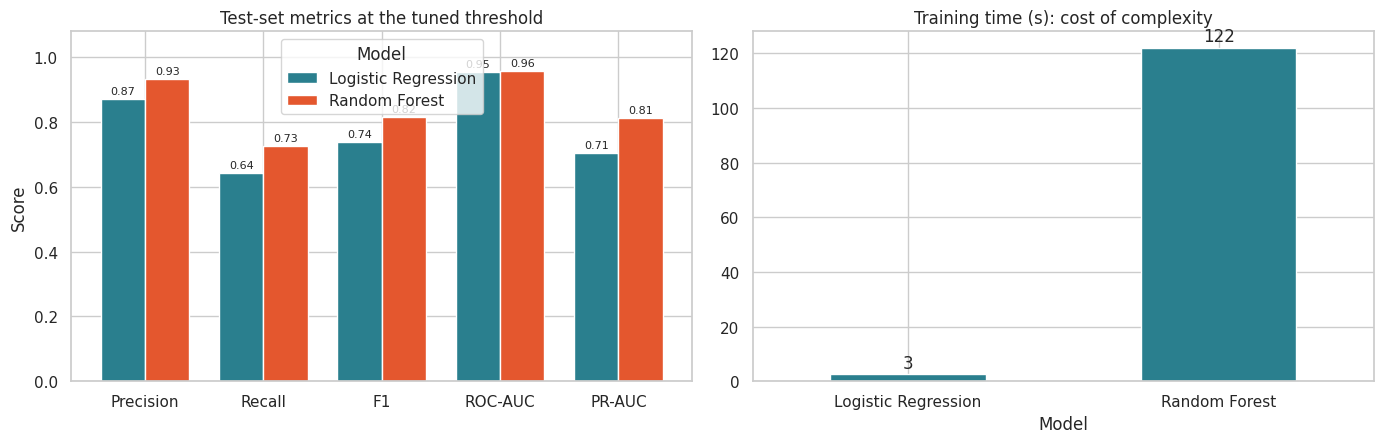

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
metric_cols = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
cmp_df[metric_cols].T.plot(kind="bar", ax=ax[0], color=[LEGIT, FRAUD], width=.75, rot=0)
ax[0].set_ylim(0, 1.08); ax[0].set_title("Test-set metrics at the tuned threshold"); ax[0].set_ylabel("Score")
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.2f", fontsize=8, padding=2)
cmp_df[["Train time (s)"]].plot(kind="bar", ax=ax[1], color=[LEGIT], legend=False, rot=0); ax[1].set_title("Training time (s): cost of complexity")
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.0f", padding=2)
savefig("10_model_comparison")

**Justification of the final model.** The winner is selected on **validation PR-AUC** (the metric that best reflects performance on the rare class), then confirmed by looking at whether the test-set precision, recall and ROC-AUC tell a consistent story. If the two models are within each other's confidence intervals, the tie-break is operational: prefer the simpler, auditable and faster model; prefer the forest only if its advantage is clear and consistent. The final sections state which case applies on this run.

Because Logistic Regression is cheap and transparent, it also remains valuable as a **challenger** or fallback model in production.

## 11. Feature importance

Three complementary views, because any single one can mislead:
1. **Random Forest impurity importance:** fast, but biased toward high-variance and many-valued features.
2. **Permutation importance** (on validation data): how much PR-AUC drops when one feature is shuffled; model-agnostic and closer to real impact.
3. **Logistic Regression coefficients** (features standardised, so sizes are comparable): direction and strength.

Permutation importance computed in 30s


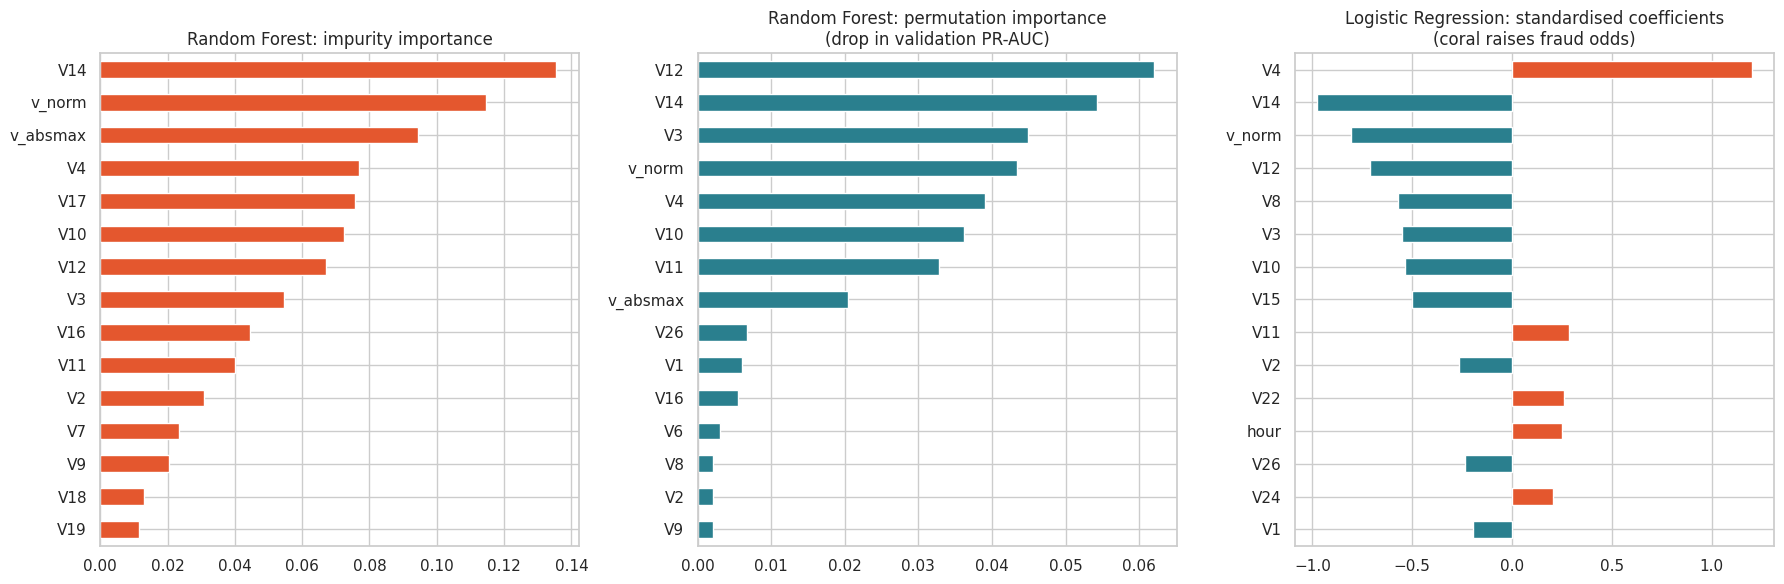

Top 5 by permutation importance: V12, V14, V3, v_norm, V4
Top 5 by impurity importance:   V14, v_norm, v_absmax, V4, V17
Top 5 by |LR coefficient|:      V4, V14, v_norm, V12, V8
Engineered features in the permutation top-10: ['v_norm', 'v_absmax']
Features all three methods agree on (top-5 overlap): ['V14', 'V4', 'v_norm']


In [27]:
feat = X_fit.columns.tolist()
rf_est = final["Random Forest"]["est"]; lr_est = final["Logistic Regression"]["est"]
imp_rf = pd.Series(rf_est.named_steps["clf"].feature_importances_, index=feat).sort_values(ascending=False)
coef = pd.Series(lr_est.named_steps["clf"].coef_[0], index=feat)
t0 = time.perf_counter()
perm = permutation_importance(rf_est, X_val, y_val, scoring="average_precision", n_repeats=PERM_REPEATS, random_state=RS, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=feat).sort_values(ascending=False)
print(f"Permutation importance computed in {time.perf_counter()-t0:,.0f}s")

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
imp_rf.head(15)[::-1].plot.barh(ax=ax[0], color=FRAUD); ax[0].set_title("Random Forest: impurity importance")
perm_s.head(15)[::-1].plot.barh(ax=ax[1], color=LEGIT); ax[1].set_title("Random Forest: permutation importance\n(drop in validation PR-AUC)")
c15 = coef.reindex(coef.abs().sort_values(ascending=False).head(15).index)[::-1]
c15.plot.barh(ax=ax[2], color=[FRAUD if v > 0 else LEGIT for v in c15]); ax[2].set_title("Logistic Regression: standardised coefficients\n(coral raises fraud odds)")
savefig("11_feature_importance")

eng_in_top = [f for f in new_feats if f in set(perm_s.head(10).index)]
print("Top 5 by permutation importance:", ", ".join(perm_s.head(5).index))
print("Top 5 by impurity importance:  ", ", ".join(imp_rf.head(5).index))
print("Top 5 by |LR coefficient|:     ", ", ".join(coef.abs().sort_values(ascending=False).head(5).index))
print("Engineered features in the permutation top-10:", eng_in_top if eng_in_top else "none")
overlap = set(perm_s.head(5).index) & set(imp_rf.head(5).index) & set(coef.abs().sort_values(ascending=False).head(5).index)
print("Features all three methods agree on (top-5 overlap):", sorted(overlap) if overlap else "none")

**Interpretation.** Features that appear near the top in *several* methods are the dependable drivers; features that only one method likes deserve suspicion. Check whether any engineered feature (`v_norm`, `v_absmax`, `hour`, ...) made the top-10: if so, the feature engineering added real value, and if not, I should say so rather than claim credit.

**What a business can do with this.**
- **Monitoring:** build dashboards and alert rules around the top-ranked signals so analysts see the strongest fraud indicators first.
- **Rules + ML hybrid:** convert a clear, stable driver into a cheap pre-filter, and keep the model for the grey zone.
- **Governance:** the coefficient plot gives auditors and regulators a readable account of *why* the linear model flags transactions.
- **Honest limit:** `V1`-`V28` are anonymised PCA components, so I cannot say what a given component means in the real world. In a live system with raw features (merchant category, country, device, velocity) the same analysis would translate directly into concrete actions.

## 12. Business impact

I translate errors into money using **explicit, adjustable assumptions**:
- A **missed fraud** costs the transaction amount (a deliberate under-estimate: it ignores chargeback fees and goodwill).
- A **false alert** costs `FP_COST` (set at the top of the notebook; default assumes a few minutes of analyst review).
- The *no-model* baseline lets every fraud through.

These numbers are illustrative; change `FP_COST` to your institution's reality.

,missed_fraud_value,false_alerts,review_cost,total_cost,saving vs no model,% of fraud value stopped
No model (let everything through),"14,766.3100",0.0000,0.0000,"14,766.3100",0.0000,0.0000
Logistic Regression,"5,998.4000",9.0000,45.0000,"6,043.4000","8,722.9100",0.5938
Random Forest,"5,861.8900",5.0000,25.0000,"5,886.8900","8,879.4200",0.6030


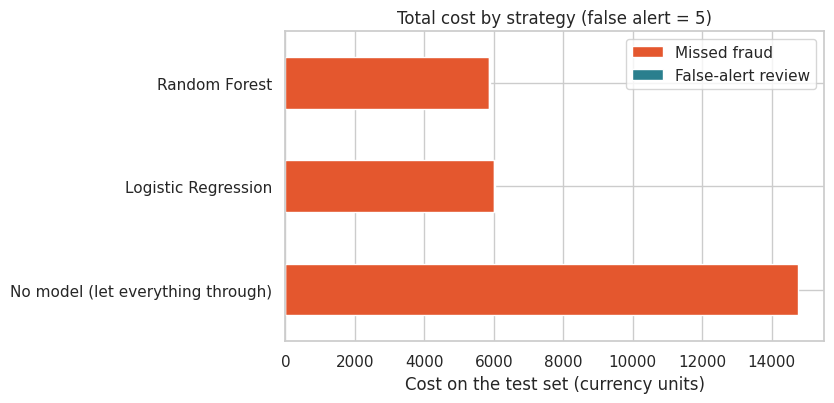

In [28]:
amt_test = raw.drop_duplicates().reset_index(drop=True).loc[X_test.index, "Amount"]     # original amounts for test rows
total_fraud_value = amt_test[y_test == 1].sum()
rows = {"No model (let everything through)": dict(missed_fraud_value=total_fraud_value, false_alerts=0, review_cost=0.0, total_cost=total_fraud_value)}
for name, d in final.items():
    pred = (d["p_test"] >= d["thr"]).astype(int)
    missed = amt_test[(y_test == 1) & (pred == 0)].sum(); fps = int(((y_test == 0) & (pred == 1)).sum())
    rows[name] = dict(missed_fraud_value=missed, false_alerts=fps, review_cost=fps * FP_COST, total_cost=missed + fps * FP_COST)
cost = pd.DataFrame(rows).T
cost["saving vs no model"] = cost.loc["No model (let everything through)", "total_cost"] - cost["total_cost"]
cost["% of fraud value stopped"] = 1 - cost["missed_fraud_value"] / total_fraud_value
display(cost)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
cost[["missed_fraud_value", "review_cost"]].plot(kind="barh", stacked=True, ax=ax, color=[FRAUD, LEGIT])
ax.set_xlabel("Cost on the test set (currency units)"); ax.set_title(f"Total cost by strategy (false alert = {FP_COST:g})"); ax.legend(["Missed fraud", "False-alert review"])
savefig("12_business_cost")

**Interpretation.** The stacked bars separate the two kinds of pain. A good model shrinks the coral (missed fraud) bar dramatically while adding only a thin teal (review) bar. If the teal bar grows large, precision is too low for the review team to cope, and a higher threshold is warranted. The absolute amounts depend on the assumed `FP_COST` and on a small test set, so read the *ranking* and *shape*, not the exact figures.

In [29]:
best = final[winner]; mb = metrics_at(y_test, best["p_test"], best["thr"])
other = [k for k in final if k != winner][0]; mo = metrics_at(y_test, final[other]["p_test"], final[other]["thr"])
print(f"FINAL MODEL: {winner} (validation PR-AUC {best['val']['pr_auc']:.3f})")
print(f"  Test recall    {mb['recall']:.1%}  -> caught {mb['tp']} of {mb['tp']+mb['fn']} frauds")
print(f"  Test precision {mb['precision']:.1%} -> {mb['fp']} false alerts for {mb['tp']} true catches")
print(f"  Test F1 {mb['f1']:.3f} | ROC-AUC {mb['roc_auc']:.3f} | PR-AUC {mb['pr_auc']:.3f} | threshold {best['thr']:.3f}")
print(f"Challenger: {other} (recall {mo['recall']:.1%}, precision {mo['precision']:.1%}, PR-AUC {mo['pr_auc']:.3f})")
print("Best parameters:", best["params"])

FINAL MODEL: Random Forest (validation PR-AUC 0.875)
  Test recall    72.6%  -> caught 69 of 95 frauds
  Test precision 93.2% -> 5 false alerts for 69 true catches
  Test F1 0.817 | ROC-AUC 0.957 | PR-AUC 0.813 | threshold 0.611
Challenger: Logistic Regression (recall 64.2%, precision 87.1%, PR-AUC 0.705)
Best parameters: {'smote__sampling_strategy': 0.05, 'smote__k_neighbors': 3, 'clf__n_estimators': 200, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 24, 'clf__class_weight': 'balanced_subsample'}


### Recommendations
1. **Deploy the selected model behind a human review queue first (shadow/assist mode)**, not as an automatic decline, until live precision is confirmed.
2. **Set the threshold from business costs, not from F1.** Re-run the cost table with the institution's real review cost and chargeback figures.
3. **Keep the simpler model as a challenger** and compare them on live traffic.
4. **Monitor drift:** track the fraud rate, feature distributions and recall on confirmed cases monthly; retrain on a schedule (fraud patterns change quickly).
5. **Never apply SMOTE or scaling outside the training fold** in any retraining job; keep the `imblearn` pipeline as the single deployable artefact.
6. **Tier the response:** auto-approve low scores, step-up authentication for the grey zone, human review for the highest scores.

### Limitations (stated openly)
- Few fraud examples, so test metrics are noisy (see the bootstrap intervals).
- Anonymised PCA features: limited feature engineering and limited explainability.
- Only about two days of data and a random (not time-based) split. In production I would validate **out of time** to detect concept drift.
- Cost model is simplified and assumption-driven.
- Tuning ran on a subset of the training data for compute reasons.

### Future improvement roadmap
| Horizon | Improvement | Expected benefit |
|---|---|---|
| Short | Gradient boosting (XGBoost/LightGBM) with cost-sensitive learning | Often the strongest tabular fraud models |
| Short | Probability calibration (isotonic/Platt) | Trustworthy scores for threshold and cost decisions |
| Short | Time-based cross-validation | Realistic estimate under drift |
| Medium | Compare SMOTE variants (Borderline-SMOTE, SMOTE-ENN) and cost-sensitive learning | Better behaviour near the class boundary |
| Medium | Customer-level behavioural features (velocity, deviation from usual spend) | Large gains when raw data is available |
| Medium | Anomaly-detection ensemble (Isolation Forest, autoencoder) for unseen fraud types | Catches novel patterns without labels |
| Long | SHAP explanations per alert; feedback loop from analyst decisions; online learning | Faster triage and continuous improvement |

## 13. Final report (auto-generated from this run)
The cell below writes `REPORT.md` with the real numbers from the run above, structured as a management deliverable. Re-running the notebook regenerates it, so the report can never drift from the results.

In [30]:
n_total, n_fraud = len(df), int(df["Class"].sum())
mw, mo_ = metrics_at(y_test, final[winner]["p_test"], final[winner]["thr"]), metrics_at(y_test, final[other]["p_test"], final[other]["thr"])
lo, hi = boot_ci(y_test, final[winner]["p_test"], final[winner]["thr"])
sav = cost.loc[winner, "saving vs no model"]; stopped = cost.loc[winner, "% of fraud value stopped"]
leak_gap = leak_tbl.iloc[0]["pr_auc"] - leak_tbl.iloc[1]["pr_auc"]
leak_line = (f"Applying SMOTE before splitting inflated PR-AUC from {leak_tbl.iloc[1]['pr_auc']:.3f} (correct) to {leak_tbl.iloc[0]['pr_auc']:.3f} (leaky) and precision from {leak_tbl.iloc[1]['precision']:.3f} to {leak_tbl.iloc[0]['precision']:.3f} in our own experiment: a leakage artefact, not skill."
             if leak_gap > 0 else "In our own experiment the leaky SMOTE-before-split setup did not score higher on this run, but it remains methodologically invalid.")
top5 = ", ".join(perm_s.head(5).index)

report = f'''# Fraud Detection Pipeline: Management Report

## 1. Executive Summary
We built and tested a machine-learning pipeline that flags fraudulent card transactions in a dataset where only {n_fraud/n_total:.2%} of {n_total:,} transactions are fraud. After comparing Logistic Regression and Random Forest, **{winner}** was selected. On a completely untouched test set it caught **{mw['recall']:.0%} of fraud** ({mw['tp']} of {mw['tp']+mw['fn']} cases) while raising **{mw['fp']} false alerts**, with ROC-AUC {mw['roc_auc']:.3f} and PR-AUC {mw['pr_auc']:.3f}. Under the stated cost assumptions it stops about **{stopped:.0%} of fraud value** on the test set. Test results come from few fraud cases and are uncertain (95% interval for recall: {lo[1]:.2f}-{hi[1]:.2f}).

## 2. Problem Statement
Fraud is rare but costly. A model judged on accuracy can look near-perfect while catching nothing (always predicting "legitimate" scores {accuracy_score(df['Class'], always_legit):.2%} accuracy and 0% recall). The task is to detect fraud with a controlled balance between missed fraud and false alarms.

## 3. Methodology
Stratified train/validation/test split; all preprocessing, SMOTE and tuning inside an `imblearn` pipeline so no information leaks from validation or test data; models judged on precision, recall, F1, ROC-AUC, PR-AUC and confusion matrices; selection on validation PR-AUC; final numbers on a one-time test evaluation.

## 4. Data Preparation
{len(raw)-len(df):,} duplicate rows removed; no missing values (a median imputer is still in the pipeline for safety); outliers kept because they carry fraud signal; 7 engineered features (hour, night flag, log amount, zero/round amount flags, PCA-space norm and max); stratified split.

## 5. Modeling Approach
Logistic Regression (scaled, L2-regularised) and Random Forest, each with SMOTE applied to training folds only. Tuned with GridSearchCV (LR) and RandomizedSearchCV (RF) on PR-AUC; decision threshold chosen on validation data. Best settings: LR {final["Logistic Regression"]["params"]}; RF {final["Random Forest"]["params"]}.

## 6. Evaluation Results
| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| {winner} (selected) | {mw['precision']:.3f} | {mw['recall']:.3f} | {mw['f1']:.3f} | {mw['roc_auc']:.3f} | {mw['pr_auc']:.3f} |
| {other} | {mo_['precision']:.3f} | {mo_['recall']:.3f} | {mo_['f1']:.3f} | {mo_['roc_auc']:.3f} | {mo_['pr_auc']:.3f} |

## 7. Key Findings
- Accuracy is meaningless here; recall and precision tell the real story.
- {leak_line}
- The most influential features (permutation importance): {top5}.
- Differences between the two models can be small relative to test-set noise; selection was made on the larger validation split.

## 8. Business Recommendations
Deploy first in assisted (human-review) mode; set the threshold from the institution's real review and chargeback costs; keep the simpler model as a challenger; monitor drift and retrain regularly; tier the response by score.

## 9. Future Improvements
Gradient boosting with cost-sensitive learning, probability calibration, time-based validation, customer behavioural features, SMOTE variants, anomaly detection for novel fraud, SHAP explanations and an analyst feedback loop.

## 10. Conclusion
A leak-free pipeline with SMOTE, tuned classifiers and threshold selection delivers a fraud detector whose value is measured in caught fraud and manageable false alerts, not accuracy. The main caveats are the small number of fraud examples and the anonymised features; both are addressed in the roadmap.
'''
open("REPORT.md", "w").write(report)
results_out = pd.concat({"test_metrics": cmp_df}, axis=1); results_out.to_csv("model_comparison.csv")
print("Wrote REPORT.md and model_comparison.csv; figures saved in ./figures")

Wrote REPORT.md and model_comparison.csv; figures saved in ./figures


## 14. Conclusion
The pipeline does what the brief asks: it handles the extreme imbalance with SMOTE **without leaking**, trains and tunes Logistic Regression and Random Forest, ignores accuracy, and explains every result in terms of money and risk. The most transferable lessons are (1) resample only inside the training fold, (2) pick the threshold from costs and validation data, and (3) report uncertainty honestly when positives are rare.